# 06 · Fundamentals, options, and *when* the risk arrives

Notebooks 02–05 read the bonds and the stock. This one checks them against three other things:
1. **The companies' own numbers.** Cash flow, capex, debt, and a "pause test": could each company pay its debts if it stopped building tomorrow? (Apple is the control: it could stop for five years and still pay.)
2. **The options market.** Option prices give a forward-looking volatility for each stock, which replaces the backward-looking volatility in 05. They also give the market's odds of a crash by different dates, so we can see *when* the market thinks the risk is.
3. **SpaceX's cash runway.** SpaceX has ~$90B of cash but is spending ~$20–40B a quarter. When does the money run out, and does that line up with what the bonds say?

Data:
- **Financials:** SEC XBRL (`data/edgar/companyfacts_*.json`). SpaceX's FY2025 comes from its S-1 (`data/spcx_fy2025_s1.csv`).
- **Options:** Market Data, Nov 9, 2026 close (`data/options/`). Bonds: TRACE last trades, Nov 10.
- **SpaceX funding inputs:** hand-entered with sources (`data/spcx_funding.csv`).
- **Handoffs from earlier notebooks:** `data/merton_inputs.csv` (05), `data/equity_vs_bond.csv` (05), `data/forward_pd.csv` (03).

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from common import INK, INK2, MUTED, AXIS, GRID, SURFACE, BOND, RAMP, EQUITY, source_note, treasury_yield, norm_cdf, merton

CHARTS = Path('charts')
AS_OF = pd.read_csv('quotes.csv', parse_dates=['as_of']).query("kind == 'trade'").as_of.max()   # latest TRACE quote date
issuers = pd.read_csv('issuers.csv').set_index('issuer')
TICK = issuers.ticker.to_dict()
ORDER = ['Apple', 'Alphabet', 'Meta', 'SpaceX', 'CoreWeave']        # safest → riskiest by bond spread
COLOR = dict(zip(ORDER, ['#86b6ef', '#4f93e0', '#2a78d6', '#1b5aa8', '#104281']))
inp = pd.read_csv('data/merton_inputs.csv', index_col='issuer')
evb = pd.read_csv('data/equity_vs_bond.csv').set_index('issuer')
fwd = pd.read_csv('data/forward_pd.csv')
bonds = pd.read_csv('bonds.csv', parse_dates=['maturity']).set_index('bond_id')
vcdf = np.vectorize(norm_cdf)
pd.options.display.float_format = '{:,.2f}'.format

## 1 · The companies' own numbers

All flows are **trailing twelve months (TTM)** to each company's latest filing: the last annual report, plus this year's year-to-date, minus last year's year-to-date. Definitions:
- **Free cash flow (FCF)** = cash from operations − capital expenditure (capex). Negative means the company is spending more on building than its business brings in.
- **EBITDA** = operating income + depreciation & amortization (D&A): a rough measure of cash earnings before interest, tax, and investment.
- **The pause test.** Suppose the company stopped *growing* tomorrow, but kept replacing everything that wears out, so today's business keeps running. How long would it take to repay all its debt from the cash left over? Section 1b spells out what that means company by company.
  - **Upkeep capex** is what it costs each year to replace today's fleet as it wears out: each asset class's cost ÷ its useful life (from each company's own filings, `data/fleet.csv`), or accounting D&A if that's higher. Accounting D&A alone understates upkeep for the AI builders: most of their servers are under two years old, so this year's depreciation reflects a fleet much smaller than today's.
  - **Run-rate cash from operations** is the latest quarter × 4. Today's fleet should be compared with today's earning power, not last year's. SpaceX's AI revenue grew ~9× in a year, so its 12-month cash flow describes a much smaller company. The 12-month version is shown as a check.
  - **Pause FCF = run-rate operating cash flow − upkeep capex.** **Years to repay all debt if paused = debt ÷ pause FCF.** If pause FCF is negative, the company can't even keep today's business running from its own cash. Apple is the control.
- **Debt due by end of 2028**: from each company's latest debt maturity table.

Cash and debt come from `issuers.csv` (hand-checked from the 10-Qs). Interest expense uses the tag each company reports. Apple stopped reporting interest expense separately after FY2023, so it's left blank.

In [2]:
FACTS = {t: json.load(open(f'data/edgar/companyfacts_{t}.json')) for t in TICK.values()}
S1 = pd.read_csv('data/spcx_fy2025_s1.csv', comment='#').set_index('tag').fy2025_mn

def facts_df(ticker, tag):
    """All duration facts for one us-gaap tag, deduplicated (latest filing wins). SpaceX gets FY2025 from its S-1."""
    d = pd.DataFrame(FACTS[ticker]['facts']['us-gaap'].get(tag, {}).get('units', {}).get('USD', []))
    if ticker == 'SPCX' and tag in S1:
        d = pd.concat([d, pd.DataFrame([{'start': '2025-01-01', 'end': '2025-12-31', 'val': S1[tag] * 1e6, 'form': 'S-1', 'filed': '2026-06-12'}])])
    if d.empty or 'start' not in d:
        return pd.DataFrame()
    d = d[d.form.isin(['10-K', '10-Q', 'S-1'])].copy()
    d['start'], d['end'] = pd.to_datetime(d.start), pd.to_datetime(d.end)
    d['days'] = (d.end - d.start).dt.days
    return d.sort_values('filed').drop_duplicates(['start', 'end'], keep='last')

def ttm(d):
    """Trailing 12 months to the latest reported date: FY + YTD − prior-year YTD (or the annual figure if latest is a 10-K)."""
    near = lambda s, x: (s - x).abs().dt.days <= 10
    end = d.end.max(); cur = d[d.end == end]
    if cur.days.max() > 350:
        return cur.loc[cur.days.idxmax(), 'val'], end
    ytd = cur.loc[cur.days.idxmax()]
    fy = d[(d.days > 350) & near(d.end, ytd.start - pd.Timedelta(days=1))]
    prior = d[near(d.start, ytd.start - pd.DateOffset(years=1)) & near(d.end, end - pd.DateOffset(years=1))]
    if len(fy) and len(prior):
        return fy.val.iloc[-1] + ytd.val - prior.val.iloc[-1], end
    return np.nan, end

# check: annual figure passes through; FY + YTD − prior YTD otherwise
_d = pd.DataFrame({'start': pd.to_datetime(['2025-01-01', '2025-01-01', '2026-01-01']), 'end': pd.to_datetime(['2025-12-31', '2025-06-30', '2026-06-30']),
                   'val': [100.0, 40.0, 60.0]}); _d['days'] = (_d.end - _d.start).dt.days
assert ttm(_d)[0] == 120 and ttm(_d.iloc[:1])[0] == 100

TAGS = {'revenue': ['RevenueFromContractWithCustomerExcludingAssessedTax', 'Revenues'],
        'operating income': ['OperatingIncomeLoss'],
        'D&A': ['DepreciationDepletionAndAmortization', 'DepreciationAmortizationAndAccretionNet', 'Depreciation'],
        'operating cash flow': ['NetCashProvidedByUsedInOperatingActivities'],
        'capex': ['PaymentsToAcquirePropertyPlantAndEquipment'],
        'interest expense': ['InterestExpenseNonoperating', 'InterestExpenseDebt', 'InterestExpense']}

def item(ticker, tags):
    best = (np.nan, pd.NaT)
    for tag in tags:
        d = facts_df(ticker, tag)
        if d.empty: continue
        v, e = ttm(d)
        if pd.notna(v) and (pd.isna(best[1]) or e > best[1]): best = (v, e)
    stale = pd.notna(best[1]) and best[1] < AS_OF - pd.DateOffset(months=15)
    return (np.nan if stale else best[0] / 1e9), best[1]

def due_by_2028(ticker):
    """Debt principal due through 2028 from the latest maturity table (10-Q tables: rest of year, next year, year two)."""
    f = FACTS[ticker]['facts']['us-gaap']; out, asof = {}, None
    for k in ['RemainderOfFiscalYear', 'InNextTwelveMonths', 'InYearTwo', 'InYearThree']:
        u = pd.DataFrame(f.get('LongTermDebtMaturitiesRepaymentsOfPrincipal' + k, {}).get('units', {}).get('USD', []))
        if u.empty: continue
        u['end'] = pd.to_datetime(u.end); out[k] = u.sort_values(['end', 'filed']).iloc[-1]
    asof = max(v.end for v in out.values())
    out = {k: v.val / 1e9 for k, v in out.items() if v.end == asof}
    years_covered = ['InNextTwelveMonths', 'InYearTwo'] + (['RemainderOfFiscalYear'] if 'RemainderOfFiscalYear' in out else ['InYearThree'])
    return sum(out.get(k, 0) for k in years_covered), asof.date()

def latest_quarter(d):
    """Value for the latest single quarter: latest YTD minus the YTD one quarter earlier (or the quarter itself)."""
    end = d.end.max(); cur = d[d.end == end]; ytd = cur.loc[cur.days.idxmax()]
    if ytd.days < 100: return ytd.val
    prev = d[(d.start == ytd.start) & ((d.end - (end - pd.DateOffset(months=3))).abs().dt.days <= 10)]
    return ytd.val - prev.val.iloc[-1]

FLEET = pd.read_csv('data/fleet.csv')
FLEET['replace per year'] = FLEET.gross_bn / ((FLEET.life_low_yrs + FLEET.life_high_yrs) / 2)

rows = {}
for iss in ORDER:
    t = TICK[iss]
    r = {k: item(t, tags)[0] for k, tags in TAGS.items()}
    r['TTM to'] = item(t, TAGS['operating cash flow'])[1].date()
    r['operating cash flow, run-rate'] = latest_quarter(facts_df(t, 'NetCashProvidedByUsedInOperatingActivities')) * 4 / 1e9
    r['cash ($bn)'], r['debt ($bn)'] = issuers.loc[iss, 'cash_securities_bn'], issuers.loc[iss, 'debt_face_bn']
    r['debt due by end-2028 ($bn)'], r['maturity table as of'] = due_by_2028(t)
    rows[iss] = r
fund = pd.DataFrame(rows).T
for c in TAGS: fund[c] = fund[c].astype(float)
fund['EBITDA'] = fund['operating income'] + fund['D&A']
fund['FCF'] = fund['operating cash flow'] - fund['capex']
fund['operating cash flow, run-rate'] = fund['operating cash flow, run-rate'].astype(float)
fund['fleet replacement'] = FLEET.groupby('issuer')['replace per year'].sum().reindex(fund.index)
fund['upkeep capex'] = np.fmax(fund['D&A'], fund['fleet replacement'])          # Apple: no fleet rows, so D&A
fund['pause FCF'] = fund['operating cash flow, run-rate'] - fund['upkeep capex']
fund['pause FCF (TTM check)'] = fund['operating cash flow'] - fund['upkeep capex']
fund['net debt ($bn)'] = fund['debt ($bn)'] - fund['cash ($bn)']
fund['debt / EBITDA'] = fund['debt ($bn)'] / fund['EBITDA']
fund['EBITDA / interest'] = fund['EBITDA'] / fund['interest expense']
fund['years to repay debt if paused'] = (fund['debt ($bn)'] / fund['pause FCF']).where(fund['pause FCF'] > 0, np.inf)
fund['years if paused (TTM check)'] = (fund['debt ($bn)'] / fund['pause FCF (TTM check)']).where(fund['pause FCF (TTM check)'] > 0, np.inf)
fund.to_csv('data/fundamentals.csv')
fund[['TTM to', 'revenue', 'EBITDA', 'operating cash flow', 'capex', 'FCF', 'cash ($bn)', 'debt ($bn)',
      'debt due by end-2028 ($bn)', 'maturity table as of', 'debt / EBITDA', 'EBITDA / interest']]

,TTM to,revenue,EBITDA,operating cash flow,capex,FCF,cash ($bn),debt ($bn),debt due by end-2028 ($bn),maturity table as of,debt / EBITDA,EBITDA / interest
Apple,2026-06-27,466.82,167.96,146.72,10.04,136.68,146.52,84.34,31.77,2025-09-27,0.50,NaN
Alphabet,2026-06-30,445.87,172.86,185.68,132.40,53.27,242.47,101.08,5.68,2025-12-31,0.58,76.76
Meta,2026-09-30,241.60,104.30,133.09,104.44,28.65,82.45,84.00,4.25,2026-09-30,0.81,40.24
SpaceX,2026-09-30,32.04,10.18,15.76,54.96,-39.20,89.90,38.01,5.79,2026-09-30,3.73,4.01
CoreWeave,2026-06-30,7.59,3.76,6.91,20.57,-13.65,5.54,35.55,15.01,2026-06-30,9.45,2.32


**Reading it ($bn, trailing 12 months):**
- Apple, Alphabet and Meta all spend heavily but fund it from operations. Alphabet's and Meta's FCF is positive even after record capex.
- **SpaceX's FCF is about −$39B**: capex of ~$55B against ~$16B from operations. Section 1c separates out the GPUs.
- **CoreWeave**: −$14B of FCF, debt ~9.5× EBITDA, and ~$15B of debt due by the end of 2028 against $5.5B of cash.
- **CoreWeave's figures run to June.** Its Q3 10-Q isn't filed yet; last year's came on Nov 10.
  - Primary (Q2 release, 8-K Aug 11): active power 1.5 GW, contracted power ~3.7 GW, backlog ~$104B plus ">$25 billion" signed in early Q3.
  - Guidance (from the call, via press): Q3 revenue $3.45–3.6B and capex $11.5–13.5B; FY2026 revenue $12.4–13.2B and capex $35–39B; >1.85 GW active by year-end.
  - So Q3 alone should burn roughly another $9–11B of FCF, funded by new debt (the September convertible, delayed-draw loans).

### 1b · The pause test, in practical terms

What "stop growing but keep the lights on" means for each company. Useful lives come from each company's own 10-K / prospectus.

| | What the capex buys | What wears out, and how fast | A practical pause | If they stopped spending *entirely* |
|---|---|---|---|---|
| **Apple** | Stores, offices, manufacturing tooling (often at suppliers), some data centers | Mostly equipment and tooling. Apple doesn't break out lives, so we use D&A (~$13B) | Keep replacing tooling and stores; skip new data centers | Little changes for years. iPhones are built by suppliers and sold whether or not Apple builds anything. **This is the control: it could stop for five years and still pay.** |
| **Alphabet** | Servers and network gear (~60% of its technical infrastructure), data centers | Servers over **6 years**; buildings 7–40 years | Replace ~1/6 of the servers each year (~$25B) and keep the buildings up; add no new AI capacity | Search, YouTube and Cloud run on those servers. Capacity would shrink by about a sixth a year: a slow decline, not a cliff. |
| **Meta** | Servers, data centers (plus the Beignet / Sopaipilla campuses, off balance sheet) | Servers over **5–5.5 years**; buildings 25–30 years | Replace ~1/5 of the servers each year (~$25B); keep paying SPV rent (~$4.6B/yr once the leases start, 07) | The ad business would degrade as servers age out over ~5 years. Meta could also walk from the SPV leases at each 4-year renewal (07). |
| **SpaceX** | Rockets and launch sites (Space), satellites (Connectivity / Starlink), GPUs and data centers (AI) | Broadband satellites **5 years**, mobile satellites **3 years**; servers / GPUs **5–6 years**; rockets 5–25 flights | Keep launching replacement satellites and flying Falcon; **stop buying new GPUs**, replacing only worn-out ones | **Starlink goes dark within ~5 years**: the satellites de-orbit, and with no replacements Connectivity revenue falls to zero. AI compute ages out over 5–6 years. Only launch survives, on reusable boosters. So replacing satellites isn't optional upkeep; it's the cost of having a Starlink business at all. |
| **CoreWeave** | GPUs and servers ("technology equipment"), data center fit-out | Technology equipment **6 years**; fit-out up to 12 | Finish installing what's under contract, then replace only | Revenue runs off with the contracts: $103.7B of remaining contract value at Jun 30, **41% within 2 years**, 39% in years 3–4, the rest by year 6½ (10-Q). With no replacement, the business becomes a run-off portfolio of ageing GPUs. |

The numbers, per year ($bn):

In [3]:
pause = fund[['D&A', 'fleet replacement', 'upkeep capex', 'operating cash flow, run-rate', 'pause FCF', 'debt ($bn)', 'years to repay debt if paused',
              'operating cash flow', 'years if paused (TTM check)']].astype(float)
pause.style.format('{:,.1f}', na_rep='—')

,D&A,fleet replacement,upkeep capex,"operating cash flow, run-rate",pause FCF,debt ($bn),years to repay debt if paused,operating cash flow,years if paused (TTM check)
Apple,13.1,—,13.1,137.5,124.4,84.3,0.7,146.7,0.6
Alphabet,25.2,31.1,31.1,156.3,125.2,101.1,0.8,185.7,0.7
Meta,24.9,28.8,28.8,131.1,102.4,84.0,0.8,133.1,0.8
SpaceX,10.9,14.3,14.3,38.5,24.2,38.0,1.6,15.8,26.5
CoreWeave,4.0,6.3,6.3,2.7,-3.6,35.5,inf,6.9,62.6


- **Apple, Alphabet, Meta:** under a year, whichever way it's measured. Alphabet's and Meta's fleets cost ~$29–31B a year to replace, 15–25% more than their accounting depreciation, and it makes no difference.
- **SpaceX:** ~1.6 years at its Q3 run-rate, but ~27 years on trailing 12-month cash flow. Its AI business went from $0.8B to $7.6B of quarterly revenue in a year, so the answer depends on whether Q3 is the new normal. Section 1c shows where the cash comes from.
- **CoreWeave fails.** At its latest quarter's pace, operations bring in ~$2.7B a year, against ~$6.3B a year to replace its GPUs. Its 12-month cash flow passes only because of large customer prepayments earlier in the year. It can't stand still: it has to keep raising money just to keep today's fleet running.

### 1c · SpaceX by segment: separating out the GPUs

SpaceX reports three segments:
- **Space:** launch, including Starship development.
- **Connectivity:** Starlink.
- **AI:** xAI's models plus the GPU data centers; "SI" in the 10-Q.

Capex and D&A are reported per segment. Cash from operations isn't, so we use segment **EBITDA** as each segment's cash earnings: operating income + D&A + share-based pay, close to the company's own "Segment Adjusted EBITDA".

Upkeep per segment uses the same rule as section 1: the higher of D&A or the cost of replacing its fleet. Satellites go to Connectivity, servers and data center infrastructure to AI, and rockets and launch sites to Space. Results are shown at the Q3 run-rate (× 4) and over the trailing 12 months.

Data is in `data/spcx_segments.csv` (S-1 for FY2025, 10-Q for 2025–26). AI's share-based pay includes a $1.2B non-cash charge tied to the Cursor acquisition.

In [4]:
SEG = pd.read_csv('data/spcx_segments.csv').pivot_table(index=['segment', 'metric'], columns='period', values='value_mn') / 1e3
FLEET_SEG = {'AI': ['Servers and networking equipment', 'Data center infrastructure'], 'Connectivity': ['Satellites'],
             'Space': ['Flight vehicle hardware', 'Launch sites']}
fl = FLEET[FLEET.issuer == 'SpaceX'].set_index('asset_class')['replace per year']

def seg_table(v):
    t = v.unstack('metric').loc[['AI', 'Connectivity', 'Space']]
    t['EBITDA'] = t.operating_income + t.da + t.sbc
    t['fleet replacement'] = [fl[FLEET_SEG[g]].sum() for g in t.index]
    t['upkeep capex'] = np.fmax(t.da, t['fleet replacement'])
    t['growth capex'] = t.capex - t['upkeep capex']
    t['EBITDA − capex'] = t.EBITDA - t.capex
    t['EBITDA − upkeep (pause)'] = t.EBITDA - t['upkeep capex']
    t.loc['Total'] = t.sum()
    return t[['revenue', 'EBITDA', 'capex', 'upkeep capex', 'growth capex', 'EBITDA − capex', 'EBITDA − upkeep (pause)']]

seg_run = seg_table(SEG['Q3-2026'] * 4)
seg_ttm = seg_table(SEG['FY2025'] + SEG['9M2026'] - SEG['9M2025'])
assert abs(seg_ttm.loc['Total', 'capex'] - fund.loc['SpaceX', 'capex']) < 0.05          # segments add up to the cash flow statement
display(seg_run.style.format('{:,.1f}').set_caption('Q3 2026 run-rate (× 4), $bn a year'))
display(seg_ttm.style.format('{:,.1f}').set_caption('Trailing 12 months to Sep 30, 2026, $bn'))
print(f"AI share of capex: {seg_run.loc['AI', 'capex'] / seg_run.loc['Total', 'capex']:.0%} (Q3 run-rate), "
      f"{seg_ttm.loc['AI', 'capex'] / seg_ttm.loc['Total', 'capex']:.0%} (TTM)")

metric,revenue,EBITDA,capex,upkeep capex,growth capex,EBITDA − capex,EBITDA − upkeep (pause)
segment,,,,,,,
AI,30.2,19.8,65.8,9.9,55.9,-46.0,9.9
Connectivity,21.0,14.0,6.2,3.9,2.2,7.8,10.1
Space,7.1,1.4,6.4,0.7,5.7,-5.0,0.7
Total,58.3,35.2,78.4,14.6,63.8,-43.2,20.6


metric,revenue,EBITDA,capex,upkeep capex,growth capex,EBITDA − capex,EBITDA − upkeep (pause)
segment,,,,,,,
AI,11.9,5.0,44.6,8.1,36.5,-39.6,-3.1
Connectivity,16.0,10.2,5.5,3.7,1.8,4.8,6.5
Space,4.2,-0.4,4.8,0.7,4.2,-5.2,-1.1
Total,32.0,14.9,55.0,12.5,42.4,-40.0,2.4


AI share of capex: 84% (Q3 run-rate), 81% (TTM)


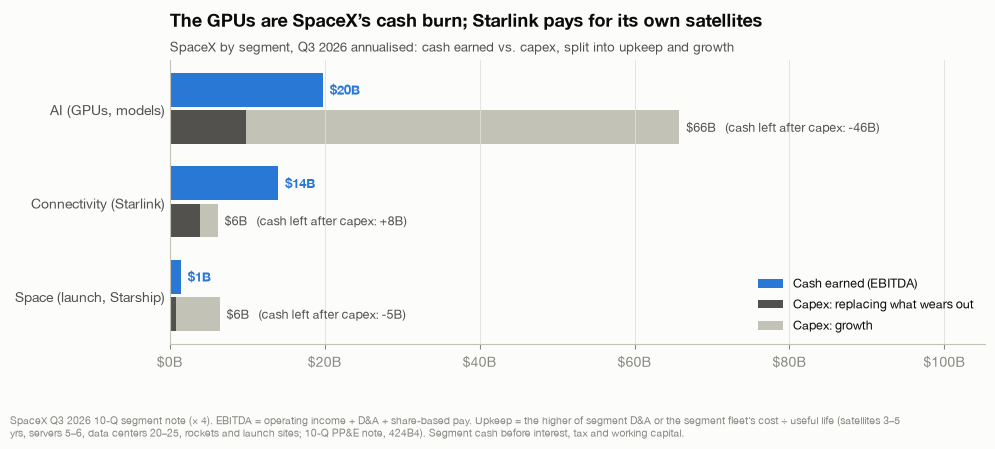

In [5]:
fig, ax = plt.subplots(figsize=(10, 4.2))
segs = ['AI', 'Connectivity', 'Space']
names = {'AI': 'AI (GPUs, models)', 'Connectivity': 'Connectivity (Starlink)', 'Space': 'Space (launch, Starship)'}
y = np.arange(len(segs))
r = seg_run.loc[segs]
ax.barh(y - 0.2, r.EBITDA, height=0.36, color=BOND, label='Cash earned (EBITDA)')
ax.barh(y + 0.2, r['upkeep capex'], height=0.36, color=INK2, label='Capex: replacing what wears out')
ax.barh(y + 0.2, r['growth capex'], left=r['upkeep capex'], height=0.36, color=AXIS, label='Capex: growth')
for i, g in enumerate(segs):
    ax.annotate(f"${r.loc[g, 'EBITDA']:,.0f}B", (r.loc[g, 'EBITDA'], i - 0.2), xytext=(5, 0), textcoords='offset points', va='center', fontsize=9, color=BOND, fontweight='bold')
    ax.annotate(f"${r.loc[g, 'capex']:,.0f}B   (cash left after capex: {r.loc[g, 'EBITDA − capex']:+,.0f}B)", (r.loc[g, 'capex'], i + 0.2), xytext=(5, 0),
                textcoords='offset points', va='center', fontsize=9, color=INK2)
ax.set_yticks(y, [names[g] for g in segs], fontsize=10)
ax.invert_yaxis(); ax.grid(axis='y', visible=False); ax.tick_params(axis='y', length=0)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'${v:,.0f}B'))
ax.set_xlim(0, r.capex.max() * 1.6)
ax.legend(loc='lower right', fontsize=9)
ax.set_title('The GPUs are SpaceX’s cash burn; Starlink pays for its own satellites', pad=24)
ax.text(0, 1.03, 'SpaceX by segment, Q3 2026 annualised: cash earned vs. capex, split into upkeep and growth', transform=ax.transAxes, fontsize=9.5, color=INK2)
source_note(fig, 'SpaceX Q3 2026 10-Q segment note (× 4). EBITDA = operating income + D&A + share-based pay. Upkeep = the higher of segment D&A or the segment fleet’s cost ÷ useful life\n'
                 '(satellites 3–5 yrs, servers 5–6, data centers 20–25, rockets and launch sites; 10-Q PP&E note, 424B4). Segment cash before interest, tax and working capital.')
fig.tight_layout(rect=(0, 0.07, 1, 1))
fig.savefig(CHARTS / '06_spacex_segments.png', dpi=200)
plt.show()

**Reading it:** 
- **The AI segment is ~84% of SpaceX's capex, and more than all of its cash burn.** At the Q3 pace it earns ~$20B a year of EBITDA and spends ~$66B on capex. Only ~$10B of that replaces worn-out GPUs; ~$56B is growth.
- **Starlink pays for itself, including replacing satellites as they de-orbit.** It earns ~$14B a year. Keeping the constellation alive costs ~$4B a year, and it still funds ~$2B of growth and has ~$8B left over. Over the last 12 months it was +$5B after all capex.
- **Space (launch) roughly breaks even on operations.** Its ~$6B of capex is almost all growth: Starship and launch sites.
- **The AI segment's turn to profit is very recent.** Over the last 12 months it couldn't cover even its own upkeep (−$3B). At the Q3 pace it covers upkeep with ~$10B to spare, so "SpaceX can pause" rests on Q3's AI revenue ($7.6B, up from $0.8B a year earlier) holding up.
- **Without new GPUs, SpaceX funds itself.** If it stops buying new GPUs (replacing only worn-out ones) but keeps launching satellites and building Starship at Q3's pace, it generates ~$4B a quarter. Section 4 runs that as a scenario.

## 2 · What the options market says about volatility

An option's price depends on how much the market expects the stock to move. Working backwards from the price gives **implied volatility (IV)**, the market's forward-looking estimate. Notebook 05 used *realised* volatility (the past year's moves), which looks backward. That's a problem for SpaceX, which has only ~4 months of trading history.

We use at-the-money options (strike near today's price), averaging calls and puts at the two strikes nearest the price. Contracts with less than a week to expiry are dropped: their IVs are noise. The **term structure** (IV by expiry) shows whether the market expects turbulence now or later.

In [6]:
CHAINS = {iss: pd.read_csv(sorted(Path('data/options').glob(f'{TICK[iss]}_*.csv'))[-1], parse_dates=['expiration', 'updated']) for iss in ORDER}
OPT_ASOF = max(d.updated.max() for d in CHAINS.values()).date()

def atm_term(d):
    a = d[(d.slice == 'atm') & (d.dte >= 7) & (d.iv > 0)]
    return a.groupby('expiration').agg(years=('dte', lambda x: x.iloc[0] / 365.25), iv=('iv', 'mean'))

TERM = {iss: atm_term(d) for iss, d in CHAINS.items()}
iv_tab = pd.DataFrame({iss: {'spot': d.underlyingPrice.iloc[0], 'IV ~3 months': np.interp(0.25, TERM[iss].years, TERM[iss].iv),
                             'IV ~1 year': np.interp(1.0, TERM[iss].years, TERM[iss].iv), 'IV longest': TERM[iss].iv.iloc[-1],
                             'longest expiry': TERM[iss].index[-1].date(), 'realised vol 1y (05)': inp.loc[iss, 'vol 1y']}
                       for iss, d in CHAINS.items()}).T
iv_tab

,spot,IV ~3 months,IV ~1 year,IV longest,longest expiry,realised vol 1y (05)
Apple,350.51,0.25,0.28,0.29,2029-01-19,0.25
Alphabet,288.19,0.35,0.36,0.37,2029-01-19,0.34
Meta,641.38,0.41,0.43,0.44,2029-01-19,0.41
SpaceX,142.12,0.55,0.55,0.55,2029-01-19,0.82
CoreWeave,49,1.01,0.93,0.87,2029-01-19,0.97


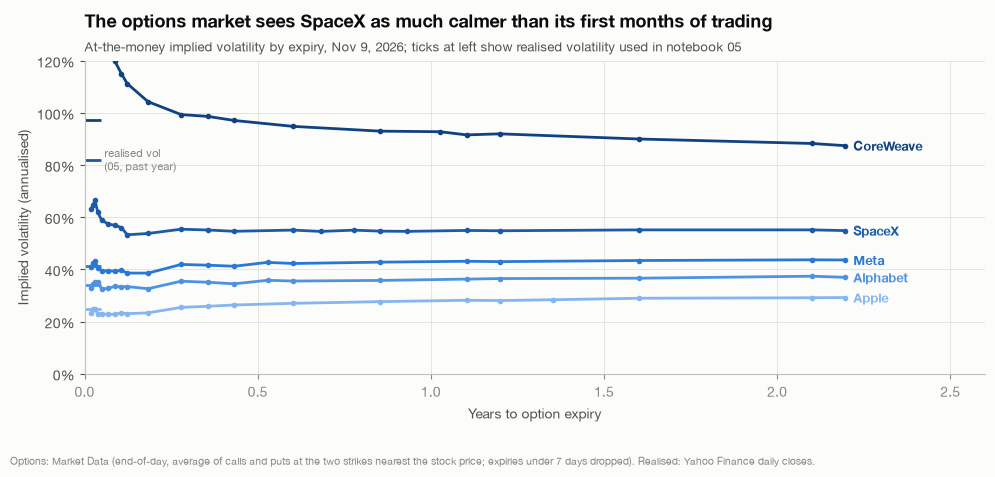

In [7]:
fig, ax = plt.subplots(figsize=(10, 4.6))
for iss in ORDER:
    t = TERM[iss]
    ax.plot(t.years, t.iv, color=COLOR[iss], lw=2, marker='o', ms=3)
    ax.annotate(iss, (t.years.iloc[-1], t.iv.iloc[-1]), xytext=(6, 0), textcoords='offset points', va='center', fontsize=9.5,
                color=COLOR[iss], fontweight='bold')
    ax.plot(0.02, inp.loc[iss, 'vol 1y'], marker='_', ms=14, mew=2, color=COLOR[iss])
ax.text(0.04, inp.loc['SpaceX', 'vol 1y'], '  realised vol\n  (05, past year)', fontsize=8, color=MUTED, va='center')
ax.set_xlim(0, 2.6); ax.set_ylim(0, 1.2)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.set_xlabel('Years to option expiry'); ax.set_ylabel('Implied volatility (annualised)')
ax.set_title('The options market sees SpaceX as much calmer than its first months of trading', pad=24)
ax.text(0, 1.03, f'At-the-money implied volatility by expiry, {OPT_ASOF:%b %-d, %Y}; ticks at left show realised volatility used in notebook 05',
        transform=ax.transAxes, fontsize=9.5, color=INK2)
source_note(fig, 'Options: Market Data (end-of-day, average of calls and puts at the two strikes nearest the stock price; expiries under 7 days dropped). Realised: Yahoo Finance daily closes.')
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(CHARTS / '06_iv_term_structure.png', dpi=200)
plt.show()

### 2b · Rerunning Merton (05) with implied volatility

Same model, same inputs as 05, but with equity volatility from options instead of the past year. Two horizons:
- **T = 5 years**, as in 05. The longest options run only ~2.2 years, so we assume volatility stays at the longest-dated IV after that (the curves above are nearly flat by year 2).
- **T = the longest option expiry (~2.2 years)**, where the options actually have a view.

The bond side uses the bond nearest 5 years (from 05).

In [8]:
m_rows = []
for iss in ORDER:
    E, D = inp.loc[iss, 'market cap ($bn)'], inp.loc[iss, 'debt ($bn)']
    T_long = TERM[iss].years.iloc[-1]
    for lbl, sig, T in [('realised vol, 5y (05)', inp.loc[iss, 'vol 1y'], 5), ('implied vol, 5y', iv_tab.loc[iss, 'IV longest'], 5),
                        (f'implied vol, {T_long:.1f}y', iv_tab.loc[iss, 'IV longest'], T_long)]:
        m = merton(E, sig, D, np.log(1 + treasury_yield(AS_OF, T) / 100), T)
        m_rows.append({'issuer': iss, 'run': lbl.replace(f'{T_long:.1f}y', 'to longest expiry'), 'equity vol': sig,
                       'stock-implied spread (bp)': m['spread_bp'], 'stock-implied default odds': m['pd']})
mert = pd.DataFrame(m_rows).pivot(index='issuer', columns='run', values='stock-implied spread (bp)').loc[ORDER]
mert['bond spread, ~5y bond (bp)'] = evb.loc[ORDER, 'bond spread']
mert.to_csv('data/merton_iv.csv')   # read by 08 and research.ipynb
mert.round(1)

run,"implied vol, 5y","implied vol, to longest expiry","realised vol, 5y (05)","bond spread, ~5y bond (bp)"
issuer,,,,
Apple,0.00,-0.00,0.00,31.10
Alphabet,0.00,0.00,0.00,68.70
Meta,0.60,0.00,0.30,92.60
SpaceX,1.20,0.00,76.70,254.80
CoreWeave,"1,136.30",605.10,"1,555.30","1,041.30"


## 3 · *When* does the options market see the risk?

A put option pays off if the stock falls below its strike. The prices of puts at many strikes reveal the market's odds that the stock ends below each level by expiry. Mathematically, the probability is the slope of the put price with respect to the strike:

$$P(S_T < K) = e^{rT}\,\frac{\partial\,\text{Put}(K)}{\partial K}$$

Quoted put prices are noisy, so we first fit a smooth volatility curve ("smile") through the puts with real two-sided quotes (bid above zero, bid–ask spread under 100% of the price). Then we price puts along that curve and take the slope. We do this at two expiries, ~1 year and ~2.2 years, so we can split the odds into *by year 1* and *between years 1 and 2.2*.

**Caveats:**
- These odds are **risk-neutral**, like the bond-implied odds in 03. They include a premium for fear, so they overstate real-world odds. That makes them directly comparable to 03.
- "The stock ends below 25% of today's price" is not "default". Shareholders are wiped out in a default, so it's a necessary condition, but crashes can happen without one. Treat the 75%-fall odds as a ceiling on equity-implied default risk.
- Apple's and Alphabet's deep puts barely trade, so their tails are left blank wherever no real quote exists.

In [9]:
def bs_put(S, K, T, r, s):
    d1 = (np.log(S / K) + (r + s * s / 2) * T) / (s * np.sqrt(T))
    return K * np.exp(-r * T) * vcdf(-(d1 - s * np.sqrt(T))) - S * vcdf(-d1)

def crash_odds(d, expiry, falls=(0.5, 0.75, 0.9)):
    q = d[(d.slice == 'put strip') & (d.expiration == expiry) & (d.bid > 0) & (d.iv > 0) & ((d.ask - d.bid) / d.mid <= 1.0)]
    S, T = d.underlyingPrice.iloc[0], q.dte.iloc[0] / 365.25
    r = np.log(1 + treasury_yield(AS_OF, T) / 100)
    x = np.log(q.strike / S)
    smile = np.poly1d(np.polyfit(x, q.iv, 2, w=np.sqrt(q.openInterest + 1)))
    out = {'years': T, 'lowest quoted strike (% of spot)': q.strike.min() / S}
    for f in falls:
        K = S * (1 - f); h = 0.005 * S
        if K < 0.9 * q.strike.min():
            out[f'P(fall ≥ {f:.0%})'] = np.nan; continue
        p = lambda k: bs_put(S, k, T, r, smile(np.log(k / S)))
        out[f'P(fall ≥ {f:.0%})'] = np.exp(r * T) * (p(K + h) - p(K - h)) / (2 * h)
    return out

# check: with a flat smile, the slope method recovers the lognormal probability N(-d2)
_S, _K, _T, _r, _s = 100, 50, 2, 0.04, 0.5
_p = lambda k: bs_put(_S, k, _T, _r, _s)
_d2 = (np.log(_S / _K) + (_r - _s * _s / 2) * _T) / (_s * np.sqrt(_T))
assert abs(np.exp(_r * _T) * (_p(_K + .5) - _p(_K - .5)) / 1 - norm_cdf(-_d2)) < 1e-4

crash = []
for iss, d in CHAINS.items():
    for e in sorted(d[d.slice == 'put strip'].expiration.unique()):
        crash.append({'issuer': iss, 'expiry': pd.Timestamp(e).date(), **crash_odds(d, e)})
crash = pd.DataFrame(crash).set_index(['issuer', 'expiry'])
crash.to_csv('data/crash_odds.csv')   # read by 08 and research.ipynb
crash.style.format({c: '{:.1%}' for c in crash.columns if c.startswith('P(')} | {'years': '{:.2f}', 'lowest quoted strike (% of spot)': '{:.0%}'}, na_rep='—')

### 3b · Year by year: options vs. bonds

Turn the two cumulative odds into **annual rates**, the same unit as 03's forward default curve. We use a **≥50% fall**: the ~1-year puts for Meta and SpaceX don't go deep enough to price a 75% fall.

$$h_{0\to1} = -\frac{\ln(1-P_1)}{T_1} \qquad h_{1\to2} = -\frac{\ln\big((1-P_2)/(1-P_1)\big)}{T_2 - T_1}$$

**Apple is the control.** Even with constant volatility, the odds of a big fall grow faster than linearly at first, so the second rate is naturally a bit higher than the first. What matters is each company's shape *relative to Apple's*:
- **above 1×** means the risk is more back-loaded than Apple's;
- **below 1×** means it's more front-loaded.

This is the same "net of Apple" idea as 03's bond curves. If SpaceX's risk were "fine for two years, then the cash runs out", its shape should be well above 1×.

In [10]:
FALL = 'P(fall ≥ 50%)'   # the deepest fall every issuer has real quotes for at both expiries
hz = []
for iss in ORDER:
    (T1, P1), (T2, P2) = crash.loc[iss][['years', FALL]].values
    h1, h2 = -np.log(1 - P1) / T1, -np.log((1 - P2) / (1 - P1)) / (T2 - T1)
    row = {'issuer': iss, 'options: first ~year': h1, 'options: ~year 1 to 2.2': h2, 'options: later ÷ earlier': h2 / h1}
    b = fwd[fwd.issuer == iss]['forward hazard'].values
    if len(b) > 1:
        row.update({'bonds (03): first bond': b[0], 'bonds (03): next bond': b[1], 'bonds: later ÷ earlier': b[1] / b[0]})
    hz.append(row)
hz = pd.DataFrame(hz).set_index('issuer')
hz.insert(3, 'options shape vs. Apple', hz['options: later ÷ earlier'] / hz.loc['Apple', 'options: later ÷ earlier'])
hz.style.format({c: '{:.1%}' for c in hz.columns if '÷' not in c and 'vs.' not in c} | {c: '{:.2f}×' for c in hz.columns if '÷' in c or 'vs.' in c}, na_rep='—')

,options: first ~year,options: ~year 1 to 2.2,options: later ÷ earlier,options shape vs. Apple,bonds (03): first bond,bonds (03): next bond,bonds: later ÷ earlier
issuer,,,,,,,
Apple,3.1%,3.6%,1.14×,1.00×,—,—,—
Alphabet,5.1%,6.4%,1.27×,1.11×,0.6%,1.0%,1.64×
Meta,8.5%,8.8%,1.03×,0.90×,1.0%,1.7%,1.69×
SpaceX,16.0%,13.6%,0.85×,0.74×,3.7%,3.8%,1.03×
CoreWeave,42.5%,19.1%,0.45×,0.39×,16.2%,14.4%,0.89×


## 4 · SpaceX: when does the money run out?

The bond curve in 03 says SpaceX's risk is **flat from day one**, ~3.5–4% a year. The obvious objection: SpaceX has ~$90B of cash, so how can it default in year one? This section checks when the cash actually runs out.

**Starting point (Sep 30, 2026, 10-Q):** $51.3B cash + $38.6B short-term securities + $5.25B undrawn credit lines ≈ $95B of liquidity.

**Money in (consensus and run-rate only):** the Apollo GPU finance lease (8-K, Oct 26). An Apollo-managed lessor buys ~$40B of GPU pods and leases them to SpaceX. Rent is paid quarterly in advance: 1/20 of the cost plus interest at a fixed rate that isn't set yet (we assume 7%). It's modelled as one tranche arriving Apr 1, 2027. The lease effectively pays for $40B of the capex below, then claws it back over five years. If SpaceX stops buying new GPUs, there's no lease. (The commitment letter is binding, but its closing conditions aren't public.)

**Money out:**
- Other debt maturities from the 10-Q table: ~$0.5B in the rest of 2026, then $2.4–3.6B a year.
- The **$7B 2031 notes** in July 2031 (`bonds.csv`).
- **Free cash flow**, under three scenarios:
  1. **Consensus.** Analysts' FCF of −$61B (2026), −$110B (2027), −$66B (2028) (Yahoo Finance, Oct 24; the consensus provider isn't named). Q4 2026 is the 2026 figure minus the reported 9 months. After 2028 it **fades in a straight line to breakeven in 2031**, an assumption.
  2. **Q3 run-rate.** Every quarter looks like Q3 2026: ~$9.6B from operations, ~$19.6B of capex. That's *less* than the $35–40B of Q4 capex the CFO guided to.
  3. **Stop buying new GPUs, keep launching.** Space and Connectivity keep spending at Q3's pace (Starship, launch sites, satellite replacement and growth). AI capex falls to upkeep: replacing worn-out GPUs only (section 1c). Operations keep producing Q3's ~$9.6B a quarter. This is the practical version of the Apple test for SpaceX: it keeps its rockets and Starlink alive and stops only the AI build-out.

Interest on the notes is already inside cash from operations.

In [11]:
FUND = pd.read_csv('data/spcx_funding.csv').set_index('item')
fv = lambda k: float(FUND.loc[k, 'value'])
spx = fund.loc['SpaceX']
q3 = {tag: (facts_df('SPCX', tag).set_index(['start', 'end']).val / 1e9) for tag in ['NetCashProvidedByUsedInOperatingActivities', 'PaymentsToAcquirePropertyPlantAndEquipment', 'DepreciationDepletionAndAmortization']}
q3 = {k: v[(pd.Timestamp('2026-01-01'), pd.Timestamp('2026-09-30'))] - v[(pd.Timestamp('2026-01-01'), pd.Timestamp('2026-06-30'))] for k, v in q3.items()}
OCF_Q, CAPEX_Q, DA_Q = q3.values()
fcf_9m = sum(v[(pd.Timestamp('2026-01-01'), pd.Timestamp('2026-09-30'))] * s for v, s in
             [(facts_df('SPCX', 'NetCashProvidedByUsedInOperatingActivities').set_index(['start', 'end']).val / 1e9, 1),
              (facts_df('SPCX', 'PaymentsToAcquirePropertyPlantAndEquipment').set_index(['start', 'end']).val / 1e9, -1)])

quarters = pd.period_range('2026Q4', '2031Q4', freq='Q')
cons_year = {2026: fv('consensus_fcf_2026') - fcf_9m, 2027: fv('consensus_fcf_2027'), 2028: fv('consensus_fcf_2028')}
fade = np.linspace(fv('consensus_fcf_2028'), 0, 4)[1:]                      # 2029, 2030, 2031: straight line to breakeven (assumption)
cons_year.update({2029: fade[0], 2030: fade[1], 2031: fade[2]})
FCF = {'Consensus': [cons_year[2026] if q.year == 2026 else cons_year[q.year] / 4 for q in quarters],
       'Q3 run-rate': [OCF_Q - CAPEX_Q] * len(quarters),
       'Stop new GPUs': [OCF_Q - (SEG.loc[('Space', 'capex'), 'Q3-2026'] + SEG.loc[('Connectivity', 'capex'), 'Q3-2026'] + seg_run.loc['AI', 'upkeep capex'] / 4)] * len(quarters)}

# fixed money in/out: debt maturities in every scenario; the Apollo lease only where SpaceX keeps buying GPUs
f = FACTS['SPCX']['facts']['us-gaap']
mat = {k: pd.DataFrame(f['LongTermDebtMaturitiesRepaymentsOfPrincipal' + k]['units']['USD']).sort_values(['end', 'filed']).val.iloc[-1] / 1e9
       for k in ['RemainderOfFiscalYear', 'InNextTwelveMonths', 'InYearTwo', 'InYearThree', 'InYearFour']}
mat_year = dict(zip([2026, 2027, 2028, 2029, 2030], mat.values()))
notes_2031 = bonds.loc['SPCX_5.350_2031', 'issue_size_usd_bn']
lease_start = pd.Period(pd.Timestamp(FUND.loc['apollo_lease_start', 'value']), 'Q')
L, share, rate = fv('apollo_lease_principal'), fv('apollo_lease_quarterly_principal_share'), fv('apollo_lease_rate')
debt_flow = [-(mat_year.get(q.year, 0) if q.year == 2026 else mat_year.get(q.year, 0) / 4) - (notes_2031 if q == pd.Period('2031Q3', 'Q') else 0)
             for q in quarters]
lease_flow, bal = [], 0.0
for q in quarters:
    flow = 0.0
    if q == lease_start: bal = L; flow += L          # Apollo pays for $40B of the GPUs inside capex...
    if bal > 1e-9:                                   # ...then SpaceX pays it back: 1/20 of cost + interest each quarter
        pay = min(L * share, bal); flow -= pay + bal * rate / 4; bal -= pay
    lease_flow.append(flow)
LEASE = {'Consensus': True, 'Q3 run-rate': True, 'Stop new GPUs': False}

LIQ0 = fv('cash') + fv('short_term_securities') + fv('undrawn_credit')
paths = pd.DataFrame({s: LIQ0 + np.cumsum(np.array(v) + np.array(debt_flow) + LEASE[s] * np.array(lease_flow)) for s, v in FCF.items()}, index=quarters.to_timestamp(how='end').normalize())
first_short = {s: (p[p < 0].index[0].date() if (p < 0).any() else None) for s, p in paths.items()}
print(f'Q3 2026: operating cash {OCF_Q:.1f}, capex {CAPEX_Q:.1f}, D&A {DA_Q:.1f} ($bn). 9-month FCF {fcf_9m:.1f}. Starting liquidity {LIQ0:.1f}.')
print('Liquidity first below zero:', first_short)
paths.iloc[::4].round(0)

Q3 2026: operating cash 9.6, capex 19.6, D&A 3.6 ($bn). 9-month FCF -35.0. Starting liquidity 95.1.
Liquidity first below zero: {'Consensus': datetime.date(2027, 12, 31), 'Q3 run-rate': datetime.date(2029, 6, 30), 'Stop new GPUs': None}


,Consensus,Q3 run-rate,Stop new GPUs
2026-12-31,69.00,85.00,99.00
2027-12-31,-12.00,74.00,112.00
2028-12-31,-91.00,21.00,125.00
2029-12-31,-148.00,-31.00,138.00
2030-12-31,-183.00,-84.00,150.00
2031-12-31,-198.00,-139.00,159.00


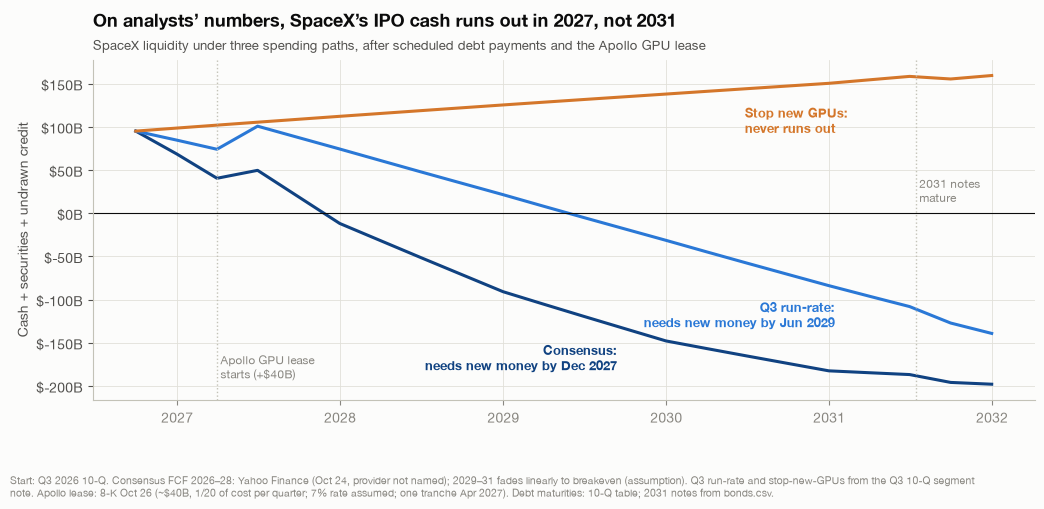

In [12]:
fig, ax = plt.subplots(figsize=(10.5, 4.8))
x0 = pd.Timestamp('2026-09-30')
style = {'Consensus': (RAMP[2], '-'), 'Q3 run-rate': (RAMP[1], '-'), 'Stop new GPUs': (EQUITY, '-')}
for s, p in paths.items():
    xs, ys = [x0, *p.index], [LIQ0, *p.values]
    c, ls = style[s]
    ax.plot(xs, ys, color=c, lw=2.2, ls=ls)
    lab = f'{s}:\nnever runs out' if first_short[s] is None else f'{s}:\nneeds new money by {pd.Timestamp(first_short[s]):%b %Y}'
    at = pd.Timestamp({'Consensus': '2029-10-01', 'Q3 run-rate': '2031-02-01', 'Stop new GPUs': '2030-06-01'}[s])
    up, right = False, s == 'Stop new GPUs'   # labels below their lines; the rising line's label extends right
    ax.annotate(lab, (at, p.asof(at)), xytext=(8 if right else -6, 10 if up else -10), textcoords='offset points',
                ha='left' if right else 'right', va='bottom' if up else 'top', fontsize=9, color=c, fontweight='bold')
ax.axhline(0, color=INK, lw=0.8)
ax.axvline(pd.Timestamp('2031-07-15'), color=AXIS, lw=1, ls=':')
ax.text(pd.Timestamp('2031-07-15'), 10, ' 2031 notes\n mature', fontsize=8.5, color=MUTED, va='bottom')
ax.axvline(pd.Timestamp('2027-04-01'), color=AXIS, lw=1, ls=':')
ax.text(pd.Timestamp('2027-04-01'), ax.get_ylim()[0] * 0.9, ' Apollo GPU lease\n starts (+$40B)', fontsize=8.5, color=MUTED, va='bottom')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'${v:,.0f}B'))
ax.set_ylabel('Cash + securities + undrawn credit')
ax.set_title('On analysts’ numbers, SpaceX’s IPO cash runs out in 2027, not 2031', pad=24)
ax.text(0, 1.03, 'SpaceX liquidity under three spending paths, after scheduled debt payments and the Apollo GPU lease', transform=ax.transAxes, fontsize=9.5, color=INK2)
source_note(fig, 'Start: Q3 2026 10-Q. Consensus FCF 2026–28: Yahoo Finance (Oct 24, provider not named); 2029–31 fades linearly to breakeven (assumption). Q3 run-rate and stop-new-GPUs from the Q3 10-Q segment note.\n'
                 'Apollo lease: 8-K Oct 26 (~$40B, 1/20 of cost per quarter; 7% rate assumed; one tranche Apr 2027). Debt maturities: 10-Q table; 2031 notes from bonds.csv.')
fig.tight_layout(rect=(0, 0.07, 1, 1))
fig.savefig(CHARTS / '06_spacex_runway.png', dpi=200)
plt.show()

### 4b · SpaceX's AI build: what the guidance implies for spend, revenue and funding

The consensus line above is a single set of analyst FCF numbers, of uncertain date and provenance. This section builds the AI business up from what SpaceX itself guided on the Q3 call (Oct 20), so the funding need can be traced to inputs. All inputs, with sources, are in `data/spcx_ai_inputs.csv`.

**Building blocks:**
- **Compute capacity (GW).** Reported: 0.6 → 1.4 → 1.7 GW (Sep 2025 → Jun 2026 → Sep 2026). Guided: 2.5–3 GW by the end of 2026, and "less than 13 gigawatts" by the end of 2027 would surprise Musk. 2028: ~20 GW (Bernstein; no company guidance). Held flat after 2028.
- **Capex per GW.** $40B base. Bernstein uses $35B; Chanos's "$500B for 10 GW" is $50B.
- **AI revenue per GW per year.** This is the key unknown. We test three values:
  1. **Management guidance.** What SpaceX's own Q1 2027 revenue guide ($33–37B) and "$100B ARR by year-end" imply, after taking out Space and Connectivity.
  2. **Consensus pricing.** What the TIKR consensus for 2027 revenue ($132B) implies, if SpaceX builds what it guided.
  3. **CoreWeave pricing.** CoreWeave earns ~$8B per GW per year on multi-year contracts (Q2 2026). SpaceX sells mostly at "effectively the spot market rate" (Musk), and spot prices for older GPUs have fallen ~20% a year (H100: $2.85/hr in Jan 2024 → $1.95 in Oct 2025). This is the case where SpaceX's pricing converges to what the contracted market pays.
- **AI EBITDA margin:** 60%. SpaceX's AI segment made 66% in Q3; CoreWeave makes 59%.
- **Space + Connectivity** grow 25% a year from their Q3 run-rate, an assumption. Connectivity grew 69% year on year in Q3.
- **FCF here is EBITDA − capex,** before interest, tax and working capital.

**Not modelled:**
- Replacing GPUs. The first big cohorts reach 5–6 years old around 2031–32; at 20 GW that's roughly $100B+ a year from then on.
- Interest on the new debt.
- Terafab, SpaceX's chip fab.

In [13]:
AIIN = pd.read_csv('data/spcx_ai_inputs.csv').set_index('item')
ai = lambda k: float(AIIN.loc[k, 'value'])
g = ai('nonai_growth')
NONAI0 = {'revenue': seg_run.loc[['Space', 'Connectivity'], 'revenue'].sum(), 'EBITDA': seg_run.loc[['Space', 'Connectivity'], 'EBITDA'].sum(),
          'capex': seg_run.loc[['Space', 'Connectivity'], 'capex'].sum()}                # Q3 2026 run-rate, $bn a year
nonai = lambda k, t: NONAI0[k] * (1 + g) ** t                                              # t = years after mid-Q3 2026
END = {2026: ai('gw_end_2026'), 2027: ai('gw_end_2027'), 2028: ai('gw_end_2028'), 2029: ai('gw_end_2028'), 2030: ai('gw_end_2028')}
YEARS = [2027, 2028, 2029, 2030]
avg_gw = lambda y: (END[y - 1] + END[y]) / 2
t_mid = lambda y: y + 0.5 - 2026.625

# Revenue per GW-year implied by management's own guidance (two independent reads)
gw_q1 = END[2026] + (END[2027] - END[2026]) / 8                                            # Q1 2027 average, if the 2027 build is linear
R_q1 = (ai('q1_2027_revenue') - nonai('revenue', 0.5) / 4) * 4 / gw_q1
R_arr = (ai('arr_end_2026') - nonai('revenue', 1 / 3)) / END[2026]
R_mgmt = (R_q1 + R_arr) / 2
R_cons = (ai('consensus_rev_2027') - nonai('revenue', t_mid(2027))) / avg_gw(2027)
R_cons28 = (ai('consensus_rev_2028') - nonai('revenue', t_mid(2028))) / avg_gw(2028)
R_crwv = ai('coreweave_rev_per_gw')
R_q3 = SEG.loc[('AI', 'revenue'), 'Q3-2026'] * 4 / ((ai('gw_2026_06') + ai('gw_2026_09')) / 2)
print(f'AI revenue per GW-year ($bn): Q3 actual {R_q3:.1f} | guidance-implied {R_mgmt:.1f} (Q1-27 guide {R_q1:.1f}, ARR goal {R_arr:.1f}) | '
      f'consensus-implied {R_cons:.1f} (2027), {R_cons28:.1f} (2028) | CoreWeave {R_crwv:.1f}')

def model(R, C, margin=ai('ai_ebitda_margin')):
    rows = []
    for y in YEARS:
        ai_rev, ai_capex = avg_gw(y) * R, (END[y] - END[y - 1]) * C
        rows.append({'year': y, 'GW at year-end': END[y], 'AI revenue': ai_rev, 'total revenue': ai_rev + nonai('revenue', t_mid(y)),
                     'AI capex': ai_capex, 'total capex': ai_capex + nonai('capex', t_mid(y)),
                     'EBITDA': ai_rev * margin + nonai('EBITDA', t_mid(y))})
    d = pd.DataFrame(rows).set_index('year')
    d['FCF'] = d.EBITDA - d['total capex']
    return d

C = ai('capex_per_gw_base')
SCEN = {'Management guidance': model(R_mgmt, C), 'Consensus pricing': model(R_cons, C), 'CoreWeave pricing': model(R_crwv, C)}
# check: at the consensus price, 2027 revenue reproduces the consensus
assert abs(SCEN['Consensus pricing'].loc[2027, 'total revenue'] - ai('consensus_rev_2027')) < 1e-6
pd.concat(SCEN, names=['scenario']).round(0)

AI revenue per GW-year ($bn): Q3 actual 19.5 | guidance-implied 26.2 (Q1-27 guide 26.9, ARR goal 25.4) | consensus-implied 12.4 (2027), 12.5 (2028) | CoreWeave 8.2


GW at year-end  AI revenue  total revenue  AI capex  \
scenario            year                                                        
Management guidance 2027           13.00      206.00         240.00    410.00   
                    2028           20.00      432.00         474.00    280.00   
                    2029           20.00      523.00         576.00      0.00   
                    2030           20.00      523.00         590.00      0.00   
Consensus pricing   2027           13.00       98.00         132.00    410.00   
                    2028           20.00      205.00         248.00    280.00   
                    2029           20.00      249.00         302.00      0.00   
                    2030           20.00      249.00         315.00      0.00   
CoreWeave pricing   2027           13.00       65.00          99.00    410.00   
                    2028           20.00      135.00         178.00    280.00   
                    2029           20.00      164.00         217.00      0.00   
                    2030           20.00      164.00         231.00      0.00   

                          total capex  EBITDA     FCF  
scenario            year                               
Management guidance 2027       425.00  142.00 -283.00  
                    2028       299.00  282.00  -17.00  
                    2029        24.00  343.00  319.00  
                    2030        30.00  351.00  321.00  
Consensus pricing   2027       425.00   77.00 -348.00  
                    2028       299.00  146.00 -153.00  
                    2029        24.00  178.00  155.00  
                    2030        30.00  186.00  156.00  
CoreWeave pricing   2027       425.00   57.00 -368.00  
                    2028       299.00  105.00 -195.00  
                    2029        24.00  128.00  104.00  
                    2030        30.00  135.00  105.00

In [14]:
LIQ_END26 = LIQ0 + OCF_Q - ai('q4_2026_capex')         # Sep 30 liquidity + one more Q3-like quarter of operating cash − guided Q4 capex
fund_rows = []
for s, d in SCEN.items():
    for lbl, c in [('$35B/GW', ai('capex_per_gw_low')), ('$40B/GW', C), ('$50B/GW', ai('capex_per_gw_high'))]:
        m = model({'Management guidance': R_mgmt, 'Consensus pricing': R_cons, 'CoreWeave pricing': R_crwv}[s], c)
        need = -m.loc[[2027, 2028], 'FCF'].sum()
        fund_rows.append({'scenario': s, 'capex per GW': lbl, 'FCF 2027': m.loc[2027, 'FCF'], 'FCF 2028': m.loc[2028, 'FCF'],
                          'cash burned 2027–28': need, 'outside money needed by end-2028': need - LIQ_END26 - L,
                          'FCF 2029 (build done)': m.loc[2029, 'FCF']})
FUNDING = pd.DataFrame(fund_rows).set_index(['scenario', 'capex per GW'])
print(f'Liquidity at end-2026 (est.): ${LIQ_END26:.0f}B; Apollo GPU lease: ${L:.0f}B')
cons = pd.DataFrame({'TIKR / S&P consensus': [ai('consensus_rev_2027'), ai('consensus_rev_2028'), np.nan, ai('consensus_capex_2028'),
                                              fv('consensus_fcf_2027'), fv('consensus_fcf_2028')],
                     'Model: management guidance': [SCEN['Management guidance'].loc[2027, 'total revenue'], SCEN['Management guidance'].loc[2028, 'total revenue'],
                                                    SCEN['Management guidance'].loc[2027, 'total capex'], SCEN['Management guidance'].loc[2028, 'total capex'],
                                                    SCEN['Management guidance'].loc[2027, 'FCF'], SCEN['Management guidance'].loc[2028, 'FCF']]},
                    index=['revenue 2027', 'revenue 2028', 'capex 2027', 'capex 2028', 'FCF 2027', 'FCF 2028'])
display(cons.round(0))
FUNDING.round(0)

Liquidity at end-2026 (est.): $67B; Apollo GPU lease: $40B


,TIKR / S&P consensus,Model: management guidance
revenue 2027,132.00,240.00
revenue 2028,249.00,474.00
capex 2027,NaN,425.00
capex 2028,194.00,299.00
FCF 2027,-110.00,-283.00
FCF 2028,-66.00,-17.00


FCF 2027  FCF 2028  cash burned 2027–28  \
scenario            capex per GW                                            
Management guidance $35B/GW        -232.00     18.00               213.00   
                    $40B/GW        -283.00    -17.00               300.00   
                    $50B/GW        -385.00    -87.00               472.00   
Consensus pricing   $35B/GW        -297.00   -118.00               414.00   
                    $40B/GW        -348.00   -153.00               500.00   
                    $50B/GW        -450.00   -223.00               673.00   
CoreWeave pricing   $35B/GW        -317.00   -160.00               476.00   
                    $40B/GW        -368.00   -195.00               562.00   
                    $50B/GW        -470.00   -265.00               735.00   

                                  outside money needed by end-2028  \
scenario            capex per GW                                     
Management guidance $35B/GW                                 106.00   
                    $40B/GW                                 192.00   
                    $50B/GW                                 365.00   
Consensus pricing   $35B/GW                                 307.00   
                    $40B/GW                                 393.00   
                    $50B/GW                                 566.00   
CoreWeave pricing   $35B/GW                                 369.00   
                    $40B/GW                                 455.00   
                    $50B/GW                                 628.00   

                                  FCF 2029 (build done)  
scenario            capex per GW                         
Management guidance $35B/GW                      319.00  
                    $40B/GW                      319.00  
                    $50B/GW                      319.00  
Consensus pricing   $35B/GW                      155.00  
                    $40B/GW                      155.00  
                    $50B/GW                      155.00  
CoreWeave pricing   $35B/GW                      104.00  
                    $40B/GW                      104.00  
                    $50B/GW                      104.00

<>:20: SyntaxWarning: "\$" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\$"? A raw string is also an option.
<>:20: SyntaxWarning: "\$" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\$"? A raw string is also an option.
/var/folders/wm/gm9z3b_j4cjb_n2bg_3ydpy80000gn/T/ipykernel_88946/1123138987.py:20: SyntaxWarning: "\$" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\$"? A raw string is also an option.
  ax.text(0, 1.03, 'SpaceX free cash flow (\$bn) at the guided compute build-out, under three prices for AI compute; \$40B of capex per GW',


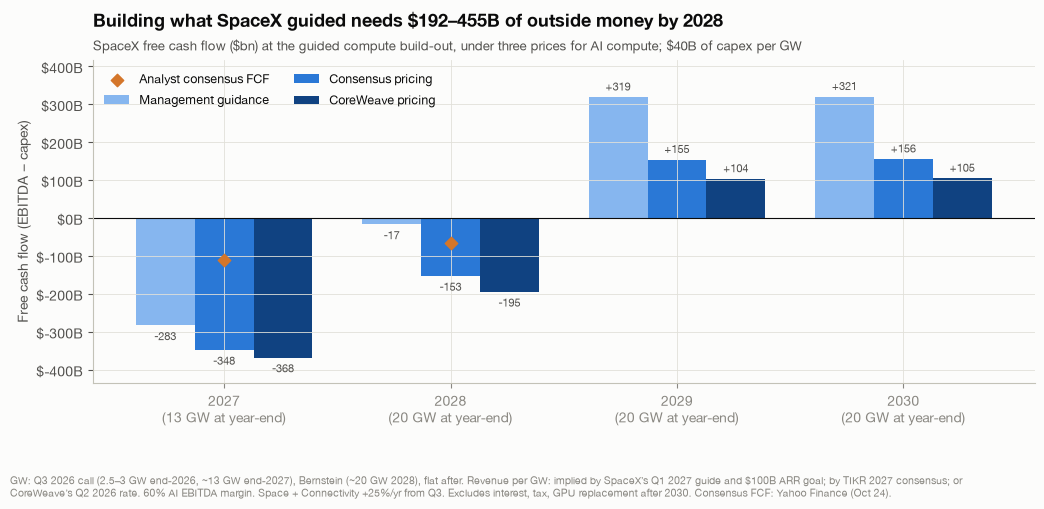

In [15]:
fig, ax = plt.subplots(figsize=(10.5, 4.8))
cols = {'Management guidance': RAMP[0], 'Consensus pricing': RAMP[1], 'CoreWeave pricing': RAMP[2]}
w = 0.26
for i, (s, d) in enumerate(SCEN.items()):
    xs = np.arange(len(YEARS)) + (i - 1) * w
    ax.bar(xs, d.FCF, width=w, color=cols[s], label=f'{s}')
    for x, v in zip(xs, d.FCF):
        ax.annotate(f'{v:+,.0f}', (x, v), xytext=(0, 3 if v > 0 else -3), textcoords='offset points', ha='center',
                    va='bottom' if v > 0 else 'top', fontsize=8, color=INK2)
ax.scatter([0, 1], [fv('consensus_fcf_2027'), fv('consensus_fcf_2028')], marker='D', s=40, color=EQUITY, zorder=4, label='Analyst consensus FCF')
ax.axhline(0, color=INK, lw=0.8)
lo_y, hi_y = min(d.FCF.min() for d in SCEN.values()), max(d.FCF.max() for d in SCEN.values())
ax.set_ylim(lo_y * 1.18, hi_y * 1.3)
ax.set_xticks(range(len(YEARS)), [f'{y}\n({END[y]:.0f} GW at year-end)' for y in YEARS])
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'${v:,.0f}B'))
ax.set_ylabel('Free cash flow (EBITDA − capex)')
ax.legend(loc='upper left', fontsize=9, ncols=2)
lo, hi = (FUNDING.loc[(s, '$40B/GW'), 'outside money needed by end-2028'] for s in ['Management guidance', 'CoreWeave pricing'])
ax.set_title(f'Building what SpaceX guided needs ${lo:,.0f}–{hi:,.0f}B of outside money by 2028', pad=24)
ax.text(0, 1.03, 'SpaceX free cash flow (\$bn) at the guided compute build-out, under three prices for AI compute; \$40B of capex per GW',
        transform=ax.transAxes, fontsize=9.5, color=INK2)
source_note(fig, 'GW: Q3 2026 call (2.5–3 GW end-2026, ~13 GW end-2027), Bernstein (~20 GW 2028), flat after. Revenue per GW: implied by SpaceX’s Q1 2027 guide and $100B ARR goal; by TIKR 2027 consensus;\n'
                 'or CoreWeave’s Q2 2026 rate. 60% AI EBITDA margin. Space + Connectivity +25%/yr from Q3. Excludes interest, tax, GPU replacement after 2030. Consensus FCF: Yahoo Finance (Oct 24).')
fig.tight_layout(rect=(0, 0.07, 1, 1))
fig.savefig(CHARTS / '06_spacex_ai_model.png', dpi=200)
plt.show()

**Reading it:** 
- **What each GW of compute earns, per year:**
  - **$19.5B** in Q3 (actual).
  - **~$26B** implied by SpaceX's own guidance: Q1 2027 revenue of $33–37B and $100B ARR by year-end give $27B and $25B.
  - **~$12.5B** implied by consensus 2027–28 revenue, if SpaceX builds what it guided. **The Street is pricing SpaceX's compute at half what management is guiding.**
  - **~$8B** at CoreWeave's contracted rate.
- **The build costs ~$425B in 2027 alone** at $40B per GW: +10 GW, plus Space and Connectivity. The last capex consensus we can name (S&P, Oct 19) had **$194B for 2028** and was set before the Q4 guide. Consensus capex is far below what management says it will build.
- **Outside money needed by the end of 2028** (cash burned in 2027–28, less ~$67B of liquidity at end-2026 and the $40B Apollo lease):
  - **~$190B** if management's pricing holds;
  - **~$390B** at consensus pricing;
  - **~$455B** at CoreWeave's pricing.
  - At $35–50B per GW, the range is **~$105–630B**. Today SpaceX has $38B of debt.
- **"Payback of less than a year" (CFO) only holds for capacity sold to customers at spot.** At ~$26B a year blended across all capacity and a 60% margin, a GW earns ~$16B a year of EBITDA against ~$40B of capex: a ~2.5-year payback. Half the capacity is used internally (Grok, Cursor) and isn't priced directly.
- **If the build stops at 20 GW, the cash turns sharply positive** in 2029: +$100–320B a year before interest, tax, and GPU replacement. Replacement starts biting from ~2031 at roughly $100B+ a year. So the credit question is concentrated in **2027–28**: will ~$200–450B of new money show up, and on what terms?
- **For the June noteholders, that's the real risk.** The new money will mostly be secured on GPUs, as the Apollo lease is. S&P's consensus has SpaceX's debt reaching **$350B by 2029**, so the $25B of unsecured notes would become a small, junior slice of the debt stack.
- **The revenue is short-dated.**
  - Backlog is $63B, 67% of it within a year. That's under half of what the Q1 2027 guide implies for a full year of revenue.
  - One AI customer was **34.5% of all Q3 revenue**.
  - Musk prefers "effectively the spot market rate" to long-term deals.
  - If spot prices fall, as they did for H100s, the revenue per GW falls with them, but the capex has already been spent.

## 5 · Do the bond prices line up with the fundamentals?

One chart: **bond-implied 5-year default odds** (03, the bond nearest 5 years) against **years to repay all debt if the company stopped growing** (section 1). If bonds price fundamentals, the points should rise together. Points well above the trend are paid more than the pause test says they need, and points below are paid less.

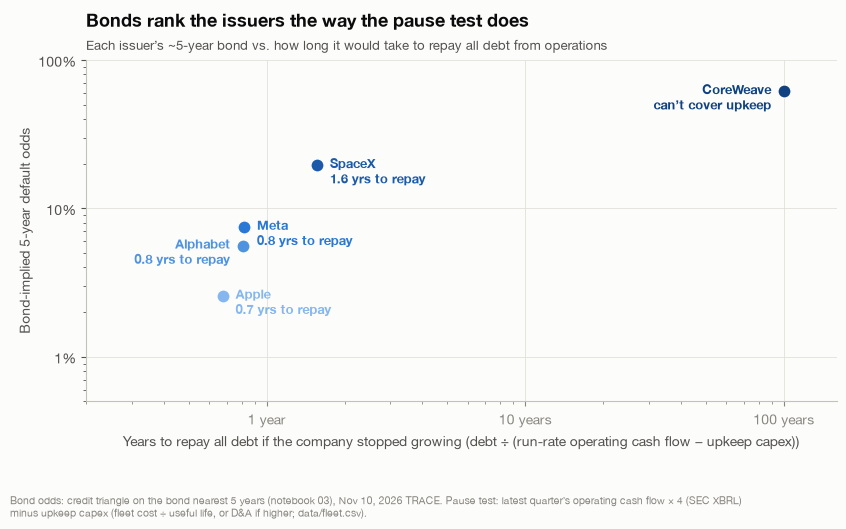

,bond 5y odds,years if paused,FCF
Apple,0.03,0.68,136.68
Alphabet,0.06,0.81,53.27
Meta,0.07,0.82,28.65
SpaceX,0.20,1.57,-39.20
CoreWeave,0.61,100.00,-13.65


In [16]:
CAP = 100   # 'never' (pause FCF negative) is drawn at the right edge
sc = pd.DataFrame({'bond 5y odds': evb.loc[ORDER, 'bond 5y odds'], 'years if paused': fund.loc[ORDER, 'years to repay debt if paused'].astype(float).clip(upper=CAP),
                   'FCF': fund.loc[ORDER, 'FCF']})
fig, ax = plt.subplots(figsize=(8.5, 5))
for iss, r in sc.iterrows():
    ax.scatter(r['years if paused'], r['bond 5y odds'], s=90, color=COLOR[iss], zorder=3, edgecolor=SURFACE, lw=1)
    tag = 'can’t cover upkeep' if r['years if paused'] >= CAP else f"{r['years if paused']:.1f} yrs to repay"
    left = iss == 'Alphabet' or r['years if paused'] >= CAP
    ax.annotate(f"{iss}\n{tag}", (r['years if paused'], r['bond 5y odds']), xytext=(-9 if left else 9, -4), textcoords='offset points',
                fontsize=9, color=COLOR[iss], fontweight='bold', va='center', ha='right' if left else 'left')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlim(0.2, CAP * 1.6); ax.set_ylim(0.005, 1)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v:g} year' + ('s' if v != 1 else '')))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v:.0%}' if v >= 0.01 else f'{v:.1%}'))
ax.set_xlabel('Years to repay all debt if the company stopped growing (debt ÷ (run-rate operating cash flow − upkeep capex))')
ax.set_ylabel('Bond-implied 5-year default odds')
ax.set_title('Bonds rank the issuers the way the pause test does', pad=24)
ax.text(0, 1.03, 'Each issuer’s ~5-year bond vs. how long it would take to repay all debt from operations', transform=ax.transAxes, fontsize=9.5, color=INK2)
source_note(fig, f'Bond odds: credit triangle on the bond nearest 5 years (notebook 03), {AS_OF:%b %-d, %Y} TRACE.\nPause test: latest quarter’s operating cash flow × 4 (SEC XBRL) minus upkeep capex (fleet cost ÷ useful life, or D&A if higher; data/fleet.csv).')
fig.tight_layout(rect=(0, 0.06, 1, 1))
fig.savefig(CHARTS / '06_risk_scatter.png', dpi=200)
plt.show()
sc

## Findings

**1 · The pause test (stop growing, keep replacing what wears out) splits the five cleanly, and the bonds agree.**
- **Apple, Alphabet, Meta** could repay all their debt in under a year, even after paying ~$29–31B a year to replace Alphabet's and Meta's server fleets (15–25% more than their accounting depreciation).
- **SpaceX: ~1.6 years at its Q3 pace, ~27 years on trailing 12-month cash flow.** The difference is the AI segment, whose quarterly revenue went from $0.8B to $7.6B in a year.
- **Separating the GPUs:**
  - The AI segment is **84% of SpaceX's capex** and more than all of its cash burn. It earns ~$20B a year but spends ~$66B, of which only ~$10B replaces worn-out GPUs.
  - **Starlink funds its own satellite replacement.** The constellation de-orbits within 5 years, so ~$4B a year of upkeep is unavoidable, and Starlink still nets ~$8B after all its capex.
  - **Without new GPUs, SpaceX is self-funding.**
- **CoreWeave fails the pause test.** At its latest quarter's pace, operations bring in ~$2.7B a year, against ~$6.3B a year to replace its GPUs. It has to keep raising money just to stand still, and ~$15B of debt is due by the end of 2028 against $5.5B of cash.
- **The bonds rank all five in the same order (scatter).**

**2 · With option-implied volatility, 05's CoreWeave puzzle mostly disappears.**
- **CoreWeave.** In 05, realised volatility of 97% made the stock look much *more* pessimistic than the bonds (1,555bp vs. 1,041bp). Forward-looking IV is 87%, and the stock-implied 5-year spread becomes **~1,136bp, within ~100bp of the bond's ~1,041bp.** The stock and the bonds roughly agree on size; the stock is a little more worried. (On Oct 23 prices the two matched almost exactly: 1,054 vs. 1,052bp.)
- **SpaceX.** IV is 55%, not 82%, and its stock-implied spread falls from ~77bp to **~1bp**. With a ~$2T market cap against $38B of debt, the stock could fall 90% and still cover the debt five times over.
- **So the ~255bp on SpaceX's 5-year bond isn't paying for the risk of its equity being wiped out.** It's paying for something the stock can't see:
  - being primed by secured GPU financing (finding 5);
  - 144A and new-issuer illiquidity;
  - who gets paid first if Musk's companies need cash.

**3 · Options and bonds roughly agree on the size of the tail.**
- **CoreWeave.** The options put the odds of a ≥75% fall by Jan 2029 at **37%** (≥90%: 26%). That brackets the ~30% cumulative default odds implied by its bond curve over the same 2.2 years.
- **SpaceX.** Options give **12%** for a ≥75% fall and **4%** for ≥90%, against ~8% bond-implied.

**4 · When is the risk? Neither market sees SpaceX as "safe now, risky later."**
- **SpaceX.** The options-implied rate of a halving is roughly flat: ~16% a year in year one and ~14% a year in years 1–2.2. Relative to Apple's shape, that's *front*-loaded (0.74×). It matches the flat bond curve in 03.
- **CoreWeave** is the most front-loaded by far (0.39× Apple): the options market's worst year is the next one (~35% odds of a halving within a year, then ~19% a year). **The bond curve barely shows that** (0.89×), which fits finding 1's refinancing wall. Bondholders may be under-pricing 2027.
- **Meta.** Options show about the same shape as Apple (0.90×), while the bond curve is back-loaded (1.69×). The extra yield on Meta's long bonds is not something the options market sees in the stock over the next two years. It's more likely a long-bond supply and duration premium, though options can't see past 2029 to test it.

**5 · Why SpaceX's risk starts around year 1: the guided AI build needs ~$200–450B of outside money in 2027–28.**
- **Analyst consensus FCF** (−$61B, −$110B, −$66B for 2026–28): even with Apollo's $40B GPU lease, SpaceX **needs new money by Dec 2027**.
- **Built up from SpaceX's own guidance** (section 4b): ~2.75 GW at end-2026, ~13 GW by end-2027 (and ~20 GW in 2028 per Bernstein), at $40B per GW. That's ~$425B of capex in 2027 alone.
  - Outside money needed by end-2028: **~$190B** if management's pricing holds (~$26B of revenue per GW per year), **~$390B** at the pricing consensus implies (~$12.5B), and **~$455B** at CoreWeave's contracted rate (~$8B).
  - Consensus is pricing SpaceX's compute at **half** of what management guides, and its capex numbers predate the build-out guidance.
- **If it stopped buying new GPUs** but kept launching satellites and building Starship, it would never run out: liquidity grows ~$4B a quarter, with no Apollo lease needed.

So SpaceX's default risk is a **financing** risk on the **GPU build-out**, concentrated in **2027–28**: will ~$200–450B of new money show up, and if not, does SpaceX cut GPU spending (which it can, without touching Starlink) before it misses a payment?
- **That risk starts about a year out and doesn't fade,** which is what both the flat bond curve and the flat options curve show.
- **The new money will mostly be secured on GPUs**, as the Apollo lease is. S&P's consensus has total debt reaching **$350B by 2029**. That leaves today's $25B of unsecured notes a small, junior slice.
- **The AI revenue behind it is short-dated:**
  - $63B of backlog, 67% of it within a year;
  - one customer was 34.5% of Q3 revenue;
  - Musk prefers spot pricing.

**6 · The Apollo lease (8-K, Oct 26) answers 03's open "priming" question.** The ~$40B GPU financing is a **finance lease, not a loan**:
- Apollo's lessor owns the GPUs.
- SpaceX pays ~$8B a year of principal plus interest from 2027 to ~2032.
- The lessor owns the GPUs outright, so on those assets it ranks ahead of every unsecured noteholder. The June indenture's lien covenant doesn't even need to be tested.
- Those payments run straight through the **$7B July 2031 maturity**, which explains why the 2031 bond pays as much as the longer ones.
- **Still open: pricing.** The fixed rate is set at pricing, before the expected year-end close. Earlier FT reporting described the deal as ~$10B of bank loans plus ~$30B of investment-grade debt. The 8-K says it's a master finance lease, and the filing wins.

## Caveats
- **Consensus.**
  - Revenue (TIKR via Yahoo, Oct 26) and capex (S&P Global MI, Oct 19, read from a search snippet because the page blocks scripts) are named.
  - The FCF consensus (−61/−110/−66) is still unattributed, and both it and S&P's capex predate the Oct 20 guidance.
  - 2029–31 in the runway chart is an assumed straight-line fade to breakeven.
- **The 4b model** has no interest, tax, working capital, or GPU replacement after 2030. Its 2028 capacity (20 GW) is Bernstein's estimate, not company guidance. "$30–50 per watt" pricing (CFO) is ambiguous between contract value and annual revenue, so we calibrate to the revenue guidance instead.
- **Apollo lease modelling.** It's modelled as one $40B tranche in Apr 2027 at an assumed 7%; the real rate and delivery schedule are set at pricing.
- **Upkeep capex** is fleet cost ÷ the company's own stated useful life. It assumes replacement costs what the old kit cost; newer GPUs and V3 satellites are cheaper per unit of capacity, so this errs high. If the stated lives are optimistic (5–6 years for GPUs is contested), it errs low. Assets still being installed (SpaceX's $23.7B, Meta's $89.5B) are excluded.
- **Run-rate = latest quarter × 4.** That's right for a fleet that exists today, but one quarter can be lumpy: customer prepayments (CoreWeave) and new contracts (SpaceX AI in Q3). The 12-month figures are shown alongside.
- **SpaceX segment cash is EBITDA, not operating cash flow,** which isn't reported by segment. The segments add up to $35B of EBITDA at run-rate, against $38.5B of reported operating cash flow.
- **Option odds are risk-neutral and terminal** ("below the level at expiry", not "ever touched"). Dividends are ignored (small for AAPL, GOOGL, META). The option view stops at Jan 2029.
- **One snapshot** (Oct 23 close). The free Market Data plan doesn't give us an IV history. If a time series would add value (e.g. SpaceX IV since the IPO against its bond spread), Starter is $30 for one month.
- **CoreWeave's numbers are to Jun 30.** Its Q3 10-Q (due November) will move them.